# Build a Simple RAG System

#### Install OpenAI, and LangChain dependencies

In [1]:
#!pip install langchain==0.3.10

In [3]:
#!pip install langchain-openai==0.2.12

In [5]:
#!pip install langchain-community==0.3.11

In [8]:
#!pip install dill

In [1]:
#!pip install langchain-chroma==0.1.4

In [1]:
# Enter OpenAI API Key
from getpass import getpass
OPENAI_API_KEY = getpass("Enter your OpenAI API Key here: ")

Enter your OpenAI API Key here: ··········


In [2]:
import os
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY

In [3]:
# Open AI Embedding Models
from langchain_openai import OpenAIEmbeddings
openai_embed_model = OpenAIEmbeddings(model="text-embedding-3-small")

# Loading and Processing the Data

In [5]:
# if you can't download using the following code
# go to https://drive.google.com/file/d/1QkSY9W5RyaBnY8c5FLIsmpPVXoHTQ-fb/view?usp=sharing download it
# manually upload it on colab
!gdown 1QkSY9W5RyaBnY8c5FLIsmpPVXoHTQ-fb

Downloading...
From: https://drive.google.com/uc?id=1QkSY9W5RyaBnY8c5FLIsmpPVXoHTQ-fb
To: /content/rag_eval_docs.csv
100% 2.66k/2.66k [00:00<00:00, 13.8MB/s]


## Load and Process the dataset

In [4]:
import pandas as pd
df = pd.read_csv('/content/rag_eval_docs.csv')
df

,id,title,context
0,1,Machine Learning,Machine learning is a field of artificial inte...
1,2,Deep Learning,Deep learning is a subset of machine learning ...
2,3,Natural Language Processing (NLP),NLP is a branch of AI that enables computers t...
3,4,Pyramids,"Pyramids are ancient structures, often serving..."
4,5,Photosynthesis,Photosynthesis is the process plants use to co...
5,6,Biology,"Biology is the study of living organisms, cove..."
6,7,Quantum Mechanics,Quantum mechanics is a branch of physics that ...
7,8,Cryptocurrency,Cryptocurrency is a digital currency that uses...
8,9,Renewable Energy,"Renewable energy sources, such as solar and wi..."
9,10,Artificial Intelligence,Artificial intelligence refers to machines mim...


In [5]:
docs = df.to_dict(orient='records')
docs[:3]

[{'id': 1,
  'title': 'Machine Learning',
  'context': 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.'},
 {'id': 2,
  'title': 'Deep Learning',
  'context': 'Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common architectures used.'},
 {'id': 3,
  'title': 'Natural Language Processing (NLP)',
  'context': 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'}]

In [6]:
from langchain.docstore.document import Document
processed_docs = []

for doc in docs:
  metadata = {
      "title": doc['title'],
      "id": doc['id']
  }
  data = doc['context']
  processed_docs.append(Document(page_content=data, metadata=metadata))
processed_docs[:3]

[Document(metadata={'title': 'Machine Learning', 'id': 1}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.'),
 Document(metadata={'title': 'Deep Learning', 'id': 2}, page_content='Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common architectures used.'),
 Document(metadata={'title': 'Natural Language Processing (NLP)', 'id': 3}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.')]

In [9]:
# Index Document Chunking and Embeddings in VectorDB (ChromaDB)

from langchain_chroma import Chroma
chroma_db = Chroma.from_documents(documents=processed_docs,
                                  collection_name='my_db',embedding=openai_embed_model,
                                  collection_metadata={"hnsw:space": "cosine"},
                                  persist_directory='./my_db')


ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given


In [8]:
# Load Vector DB from disk
from langchain_chroma import Chroma
chroma_db = Chroma(persist_directory='./my_db', collection_name='my_db',
                   embedding_function=openai_embed_model)

ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given


# Semantic Similarity Based Retrieval

In [9]:
# Retrieval part
similarity_retriever = chroma_db.as_retriever(search_type='similarity_score_threshold',
                                              search_kwargs={"k": 3, "score_threshold":0.3})

In [10]:
from IPython.display import display, Markdown
def display_docs(docs):
  for doc in docs:
    print("Metadata: ", doc.metadata)
    print("Content Brief: ")
    display(Markdown(doc.page_content))
    print()

In [11]:
query = "What is AI?"
top_docs = similarity_retriever.invoke(query)
display_docs(top_docs)

ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event CollectionQueryEvent: capture() takes 1 positional argument but 3 were given


Metadata:  {'id': 10, 'title': 'Artificial Intelligence'}
Content Brief: 


Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.


Metadata:  {'id': 3, 'title': 'Natural Language Processing (NLP)'}
Content Brief: 


NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.


Metadata:  {'id': 1, 'title': 'Machine Learning'}
Content Brief: 


Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.

In [12]:
query = "How do plants survive?"
top_docs = similarity_retriever.invoke(query)
display_docs(top_docs)

Metadata:  {'id': 5, 'title': 'Photosynthesis'}
Content Brief: 


Photosynthesis is the process plants use to convert sunlight into energy. This process produces glucose and releases oxygen as a byproduct. It is crucial for sustaining life on Earth by providing food and oxygen.

# Build the RAG Pipeline

In [13]:
# Augmentation part
from langchain_core.prompts import ChatPromptTemplate

rag_prompt = """You are an assistant who is an expert in question-answering tasks.
              Answer the following question using only the following pieces of retrieved context.
              If the answer is not in the context, do not make up answers, just say that
              you don't know. Keep the answer to the point based on the information from the context.

              Question:
              {question}

              Context:
              {context}

              Answer:
              """
rag_prompt_template = ChatPromptTemplate.from_template(rag_prompt)

In [14]:
# LLM model (Langchain model for building RAG System)
from langchain_core.runnables import RunnablePassthrough
from langchain_openai import OpenAI
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough
from langchain_core.runnables import RunnableLambda
from operator import itemgetter

In [15]:
from langchain_openai import ChatOpenAI
chatgpt = ChatOpenAI(model_name="gpt-4o-mini", temperature=0)
def format_docs(docs):
  return "\n\n".join(doc.page_content for doc in docs)

src_rag_response_chain = (
    {
        "context": (itemgetter("context") | RunnableLambda(format_docs)),
        "question": RunnablePassthrough(),
    }
    | rag_prompt_template
    | chatgpt
    | StrOutputParser()
)


rag_chain_w_sources = (
    {"context": similarity_retriever, "question": RunnablePassthrough()}
    | RunnablePassthrough.assign(response = src_rag_response_chain))

In [16]:
query = "How do plants survive?"
result = rag_chain_w_sources.invoke(query)
result

{'context': [Document(metadata={'id': 5, 'title': 'Photosynthesis'}, page_content='Photosynthesis is the process plants use to convert sunlight into energy. This process produces glucose and releases oxygen as a byproduct. It is crucial for sustaining life on Earth by providing food and oxygen.')],
 'question': 'How do plants survive?',
 'response': 'Plants survive by using photosynthesis to convert sunlight into energy, producing glucose and releasing oxygen, which is essential for sustaining life on Earth.'}

In [17]:
query = "What is AI?"
result = rag_chain_w_sources.invoke(query)
result

{'context': [Document(metadata={'id': 10, 'title': 'Artificial Intelligence'}, page_content="Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning."),
  Document(metadata={'id': 3, 'title': 'Natural Language Processing (NLP)'}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'),
  Document(metadata={'id': 1, 'title': 'Machine Learning'}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation 

# Create a Synthetic RAG Golden Reference Dataset

In [18]:
doc_contexts = [doc.page_content for doc in processed_docs]
doc_contexts[:3]

['Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.',
 'Deep learning is a subset of machine learning utilizing neural networks with many layers. It excels in complex tasks like image and speech recognition. Convolutional and recurrent neural networks are among the common architectures used.',
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.']

In [19]:
#!pip install deepeval

In [34]:
from deepeval.synthesizer import Synthesizer
from deepeval.synthesizer import types

In [1]:
synthesizer = Synthesizer(model ="gpt-4o")
eval_data = synthesizer.generate_goldens(
    # Provide a list of context for synthatic data generation
    documents = [[doc] for doc in doc_contexts],
    include_expected_output=True,
    max_goldens_per_context=1,
    num_evolutions=1,
    scenario="Retrieval Augmented Generation",
    task="Question Answering",
    evolutions = {
        "reasoning": 0.1,
        "multicontext": 0.9,
        "concretizing": 0.9,
        "constrained": 0.0,
        "comparative":0.0,
        "hypothetical": 0.0,
        "in_breadth": 0.0,
    }
)

NameError: name 'Synthesizer' is not defined

# Evaluation Metrics

### Retriever Metrics
1. Contextual Precision
2. Contextual Recall
3. Contextual Relevancy

### Generator Metrics
4. Answer Relevancy
5. Faithfulness
6. Hallucination Check
7. LLM as a Judge (G-Eval) - customize one

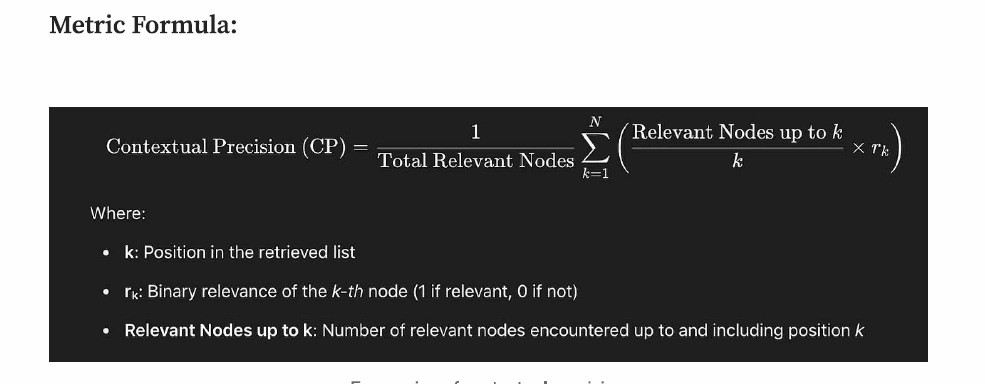

In [36]:
query = "What is AI?"
response = rag_chain_w_sources.invoke(query)
response

{'context': [Document(metadata={'id': 10, 'title': 'Artificial Intelligence'}, page_content="Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning."),
  Document(metadata={'id': 3, 'title': 'Natural Language Processing (NLP)'}, page_content='NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.'),
  Document(metadata={'id': 1, 'title': 'Machine Learning'}, page_content='Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation 

In [38]:
# Examples
retrieved_context = [doc.page_content for doc in response['context']]
retrieved_context


["Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.",
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.',
 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.']

In [39]:
human_answer = """AI, also known as Artificial Intelligence is used to build complex systems for applications
              like virtual assistants, robotics and autonomous vehicles."""

In [40]:
new_context = ["Machine Learning is the study of algorithms which learn with more data",
               "AI is known for Artificial Intelligence"] + retrieved_context
new_context

['Machine Learning is the study of algorithms which learn with more data',
 'AI is known for Artificial Intelligence',
 "Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.",
 'NLP is a branch of AI that enables computers to understand, interpret, and generate human language. Techniques include tokenization, stemming, and sentiment analysis. Applications range from chatbots to language translation services.',
 'Machine learning is a field of artificial intelligence focused on enabling systems to learn patterns from data. Algorithms analyze past data to make predictions or classify information. Popular applications include recommendation systems and image recognition.']

# Contexual Precision Metrics

In [44]:
from deepeval.test_case import LLMTestCase
from deepeval.metrics import ContextualPrecisionMetric
from deepeval import evaluate


test_case = LLMTestCase(
    input = response['question'],
    actual_output= response['response'],
    expected_output=human_answer,
    retrieval_context=new_context
)


metrics = ContextualPrecisionMetric(
    threshold=0.50,
    model ="gpt-4o",
    include_reason=True,
    verbose_mode=True
)
result = evaluate([test_case], [metrics])

✨ You're running DeepEval's latest Contextual Precision Metric! (using gpt-4o, strict=False, async_mode=True)...

Output()

INFO:deepeval.evaluate.execute:in _a_execute_llm_test_cases


**************************************************

Contextual Precision Verbose Logs

...

Verdicts:
[
    {
        "verdict": "no",
        "reason": "The context 'Machine Learning is the study of algorithms which learn with more data' does not 
directly address the definition or applications of AI."
    },
    {
        "verdict": "yes",
        "reason": "The context 'AI is known for Artificial Intelligence' directly provides the abbreviation for AI,
which is part of the expected output."
    },
    {
        "verdict": "yes",
        "reason": "The context 'Artificial intelligence refers to machines mimicking human intelligence, like 
problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles.'
directly aligns with the expected output by defining AI and listing its applications."
    },
    {
        "verdict": "no",
        "reason": "The context 'NLP is a branch of AI that enables computers to understand, interpret, and generate
human language.' focuses on a specific branch of AI rather than the general definition or applications of AI."
    },
    {
        "verdict": "no",
        "reason": "The context 'Machine learning is a field of artificial intelligence focused on enabling systems 
to learn patterns from data.' focuses on machine learning, a subset of AI, rather than the broader definition or 
applications of AI."
    }
]
 
Score: 0.5833333333333333
Reason: The score is 0.58 because the first node, ranked highest, is irrelevant as it discusses 'Machine Learning' 
without addressing AI directly. The second and third nodes are relevant, providing a definition and applications of
AI, which is why they are ranked appropriately. However, the fourth and fifth nodes, which are irrelevant, discuss 
specific branches or subsets of AI rather than the general concept, and should be ranked lower than the relevant 
nodes.

======================================================================



Metrics Summary

  - ✅ Contextual Precision (score: 0.5833333333333333, threshold: 0.5, strict: False, evaluation model: gpt-4o, reason: The score is 0.58 because the first node, ranked highest, is irrelevant as it discusses 'Machine Learning' without addressing AI directly. The second and third nodes are relevant, providing a definition and applications of AI, which is why they are ranked appropriately. However, the fourth and fifth nodes, which are irrelevant, discuss specific branches or subsets of AI rather than the general concept, and should be ranked lower than the relevant nodes., error: None)

For test case:

  - input: What is AI?
  - actual output: Artificial intelligence refers to machines mimicking human intelligence, like problem-solving and learning. AI includes applications like virtual assistants, robotics, and autonomous vehicles. It's evolving rapidly with advancements in machine learning and deep learning.
  - expected output: AI, also known as Artificial Intellig

⚠ WARNING: No hyperparameters logged.
» ]8;id=406032;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 13.21s | token cost: 0.006467500000000001 USD)
» Test Results (1 total tests):
   » Pass Rate: 100.0% | Passed: 1 | Failed: 0

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

In [42]:
print("Success", result.test_results[0].metrics_data[0].success)
print("Score", result.test_results[0].metrics_data[0].score)
print("Reason", result.test_results[0].metrics_data[0].reason)

Success True
Score 0.5833333333333333
Reason The score is 0.58 because the first node, ranked highest, is irrelevant as it discusses 'Machine Learning' without directly addressing AI, which should be ranked lower. The second and third nodes are relevant, providing a definition and applications of AI, justifying their higher ranking. However, the fourth and fifth nodes, which focus on subsets of AI like 'NLP' and 'Machine Learning', are less relevant to the broader question of 'What is AI?' and should be ranked lower than the relevant nodes.
